In [15]:
import numpy as np
from scipy.special import jv, kv
import matplotlib.pyplot as plt
import os

In [16]:
c_const = 3e8 #speed of light in vacuum
mu_0 = 4 * np.pi * 1e-7 #permeability of free space
unit_cell_pitch = 650e-9

Nx = 1025 #pixels per dimension
Ny = Nx
nx = (Nx - 1) // 2 #indices without axes (= #512)
ny = (Ny - 1) // 2
dof = 2*((nx + 1)**2) #number of degrees of freedom per metasurface
S = Nx * Ny

size_x = unit_cell_pitch * Nx #actual physical size
size_y = unit_cell_pitch * Ny

xs = np.arange(-Nx//2+1, Nx//2+1) * (size_x / Nx)
ys = np.arange(-Ny//2+1, Ny//2+1) * (size_y / Ny)

#important checks on spatial grid
try:
    assert(len(xs) == Nx)
    assert(len(ys) == Ny)
    assert(xs[0] == xs[-1]*-1)
    assert(ys[0] == ys[-1]*-1)
    assert(xs[nx]==0)
    assert(ys[ny]==0)
    assert(np.abs(np.abs(xs[1]-xs[0]) - unit_cell_pitch) < 1e-12)
except:
    raise ValueError("Error while setting up the spatial grid.")

X, Y = np.meshgrid(xs, ys)

In [17]:
lda = 1.55e-6

n_co = 1.4499 #core refractive index
n_cl = 1.444 #cladding refractive index


fiber_core_diameter = 19e-6 # [m]
a = fiber_core_diameter / 2 #fiber core radius

lda_min = 1.50e-6
lda_max = 1.60e-6

#find the v parameter (normalized frequency) range that corresponds to the 1550 nm wavelength
v_1550 = 2 * np.pi * a / lda * np.sqrt(n_co**2 - n_cl**2)
v_1530 = 2 * np.pi * a / lda_min * np.sqrt(n_co**2 - n_cl**2)
v_1570 = 2 * np.pi * a / lda_max * np.sqrt(n_co**2 - n_cl**2)
print(v_1530)
print(v_1550)
print(v_1570)

5.199720268148102
5.0319873562723565
4.874737751388846


In [18]:
n_list = [0,1,2]

b = np.linspace(1e-3, 1-1e-3, 400000)
V_list = np.linspace(1, 10, 200)
V_obs = v_1550
#b, V = np.meshgrid(b_list, V_list)

b_solutions = []
make_plot = False
if make_plot:
    fig, ax = plt.subplots()
    #for the given n index, for each value of V, find the corresponding b values that
    #satisfy the eigenvalue problem
    for n in n_list:
        print("Computing fiber patterns for mode index: ", n)
        for V in V_list:
            LHS = np.sqrt(1-b) * jv(n+1, V * np.sqrt(1-b)) / jv(n, V * np.sqrt(1-b))
            RHS = np.sqrt(b) * kv(n+1, V * np.sqrt(b)) / kv(n, V * np.sqrt(b))
            close = np.isclose(LHS, RHS, atol=0.00001)
            b_values = b[close]
            b_solutions.append(b_values)
            ax.scatter([V] * len(b_values), b_values, c=f"C{n}")

    #add a vertical line at V_1530 and V_1570
    ax.axvline(v_1530, color='gray', linestyle='--')
    ax.axvline(v_1570, color='gray', linestyle='--')
    ax.set_xlabel("v")
    ax.set_ylabel("b")
    leg = ax.legend([f"LP{n}p" for n in n_list])
    for elem, handle in enumerate(leg.legend_handles):
        handle.set_color(f"C{elem}")
    plt.savefig("FMF_fiber_modes.pdf")
    plt.show()


In [19]:
lda_range = np.arange(1500e-9, 1610e-9, 10e-9)
vnum_range = 2 * np.pi * a / lda_range * np.sqrt(n_co**2 - n_cl**2)
n = 2 #mode n index
b_solutions_at_V_obs = []
for V_obs in vnum_range:
    LHS = np.sqrt(1-b) * jv(n+1, V_obs * np.sqrt(1-b)) / jv(n, V_obs * np.sqrt(1-b))
    RHS = np.sqrt(b) * kv(n+1, V_obs * np.sqrt(b)) / kv(n, V_obs * np.sqrt(b))
    #return solutions that have the largest value of b that satisfies the eigenvalue equation
    #select only the positions where b is maximum
    b_solutions_at_V_obs.append(np.max(b[np.isclose(LHS, RHS, atol=0.00001)]))
    #b_solutions_at_V_obs.append(np.max(b[np.argmax(np.where(np.isclose(LHS, RHS, atol=0.00001),1,0).flatten())]))

print(vnum_range)
print("b solutions at V_obs:")
print(b_solutions_at_V_obs)

[5.19972027 5.16528503 5.1313029  5.09776497 5.0646626  5.03198736
 4.99973103 4.96788561 4.93644329 4.90539648 4.87473775]
b solutions at V_obs:
[np.float64(0.3421646579116448), np.float64(0.3353832309580774), np.float64(0.3285943189857975), np.float64(0.32180790201975507), np.float64(0.31501649504123763), np.float64(0.3082250880627202), np.float64(0.30143617609044027), np.float64(0.2946447691119228), np.float64(0.2878583521458804), np.float64(0.281071935179838), np.float64(0.2742905082262706)]


In [20]:
for ind, b_mode_sel in enumerate(b_solutions_at_V_obs):
    selected_lda = lda_range[ind]
    print(f'Selected lda: {selected_lda}')
    
    omega = 2 * np.pi * c_const / selected_lda

    print(f'b_mode_sel: {b_mode_sel}')

    k_co = 2 * np.pi / selected_lda * n_co
    k_cl = 2 * np.pi / selected_lda * n_cl

    beta = np.sqrt(b_mode_sel * (k_co**2 - k_cl**2) + k_cl**2)
    print(f'Beta: {beta}')

    chi_co = v_1550 * np.sqrt(1 - b_mode_sel) / a
    chi_cl = v_1550 * np.sqrt(b_mode_sel) / a

    E_field = np.zeros_like(X, dtype=complex)
    H_field = np.zeros_like(E_field, dtype=complex)

    for i in range(Nx):
        for j in range(Ny):
            r = np.sqrt(X[i,j]**2 + Y[i,j]**2)
            if r < 10*a:
                phi = np.arctan2(Y[i,j], X[i,j])
                if r < a:#inside core
                    E_field[i,j] = jv(n,chi_co * r) / jv(n, chi_co * a) * np.cos(n * phi)
                    H_field[i,j] = beta / (mu_0 * omega) * E_field[i,j]
                else:#outside core
                    E_field[i,j] = kv(n, chi_cl * r) / kv(n, chi_cl * a) * np.cos(n * phi)
                    H_field[i,j] = beta / (mu_0 * omega) * E_field[i,j]

    #save the electric field to a file
    np.save(f"FMF_LP{n}1_field_distribution_lda_{selected_lda*1e9:.0f}_N_{Nx}.npy", E_field)
    np.save(f"FMF_LP{n}1_magnetic_field_distribution_lda_{selected_lda*1e9:.0f}_N_{Nx}.npy", H_field)

Selected lda: 1.5e-06
b_mode_sel: 0.3421646579116448
Beta: 6057080.6144769015
Selected lda: 1.51e-06
b_mode_sel: 0.3353832309580774
Beta: 6016800.903265904
Selected lda: 1.5199999999999998e-06
b_mode_sel: 0.3285943189857975
Beta: 5977051.000995498
Selected lda: 1.5299999999999998e-06
b_mode_sel: 0.32180790201975507
Beta: 5937820.761223789
Selected lda: 1.5399999999999997e-06
b_mode_sel: 0.31501649504123763
Beta: 5899099.88034534
Selected lda: 1.5499999999999996e-06
b_mode_sel: 0.3082250880627202
Beta: 5860878.619228131
Selected lda: 1.5599999999999995e-06
b_mode_sel: 0.30143617609044027
Beta: 5823147.429137056
Selected lda: 1.5699999999999994e-06
b_mode_sel: 0.2946447691119228
Beta: 5785896.827739571
Selected lda: 1.5799999999999993e-06
b_mode_sel: 0.2878583521458804
Beta: 5749117.865697862
Selected lda: 1.5899999999999992e-06
b_mode_sel: 0.281071935179838
Beta: 5712801.5277197575
Selected lda: 1.599999999999999e-06
b_mode_sel: 0.2742905082262706
Beta: 5676939.255324843


Field dataset shape:  (1025, 1025)
Field dataset shape:  (1025, 1025)
Field dataset shape:  (1025, 1025)
Field dataset shape:  (1025, 1025)
Field dataset shape:  (1025, 1025)
Field dataset shape:  (1025, 1025)
Field dataset shape:  (1025, 1025)
Field dataset shape:  (1025, 1025)
Field dataset shape:  (1025, 1025)
Field dataset shape:  (1025, 1025)
Field dataset shape:  (1025, 1025)


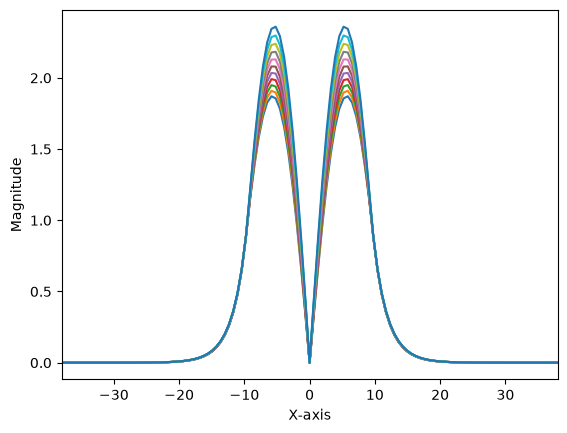

In [21]:
#open the saved electric field files and plot slices through the center of the field
#to compare the magnitude across wavelengths
lda_list_nm = np.round([selected_lda*1e9 for selected_lda in lda_range],0)
fig, ax = plt.subplots()
for lda_nm in lda_list_nm:
    filename = f"FMF_LP11_field_distribution_lda_{int(lda_nm)}_N_1025.npy"
    field = np.load(filename)
    field_shape = field.shape
    print("Field dataset shape: ",field_shape)
    center_slice = field[int(field_shape[0]/2),:]
    ax.plot(xs*1e6,np.abs(center_slice),label=f"{int(lda_nm)} nm")
ax.set_xlim(-fiber_core_diameter*2*1e6,fiber_core_diameter*2*1e6)
ax.set_xlabel("X-axis")
ax.set_ylabel("Magnitude")
plt.show()